In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, adjusted_rand_score, rand_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA


<h2>File reading</h2>

In [114]:
n_clusters=2
n_init=1

data = pd.read_csv("data_unsupervised.csv", encoding="utf8")[0:1000]
print(data)
vectorizedData = TfidfVectorizer()
vectorizedData.fit(data['body'])
vectorizedData = vectorizedData.transform(data['body'])

             author        subreddit   created_utc  \
0     ejchristian86  TwoXChromosomes  1.388534e+09   
1         ZenDragon           gaming  1.388534e+09   
2      savoytruffle        AskReddit  1.388534e+09   
3      hentercenter     stlouisblues  1.388534e+09   
4      rick-o-suave             army  1.388534e+09   
..              ...              ...           ...   
995     xgloryfades       depression  1.388537e+09   
996          dremic         AskWomen  1.388537e+09   
997   Yogi_the_duck           hockey  1.388537e+09   
998  ToolPackinMama           skyrim  1.388537e+09   
999          ksrymy    GuessTheMovie  1.388537e+09   

                                                  body  
0    I hadn't ever heard of them before joining thi...  
1                  At 7680 by 4320 with 64x AA, right?  
2                                              bite me  
3                      Damn that was a good penalty :(  
4    I swore into DEP on 6-OCT and I left 5-NOV und...  
..       

<h2>KMeans</h2>

In [115]:
kmeans = KMeans(n_clusters, init='random', random_state=None, n_init=10)
kmeans.fit(vectorizedData)

KMeans(init='random', n_clusters=2, n_init=10)

<h3>Determining the number of clusters</h3>

In [116]:
kmeans_results = []
k_values=pd.Series(range(2, 10, 1))#this will need to be changed
for k in k_values:
    kmeans_results.append(KMeans(n_clusters=k).fit(vectorizedData))

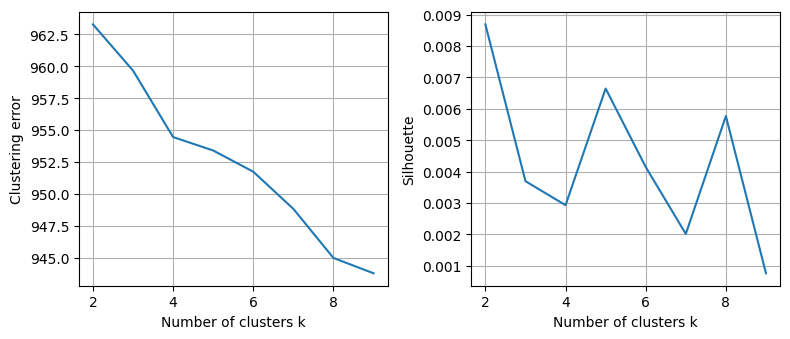

In [117]:
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in k_values], 
    [result.inertia_ for result in kmeans_results]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in k_values], 
    [silhouette_score(vectorizedData, result.labels_) for result in kmeans_results]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")
axs[1].grid()

plt.tight_layout()
plt.show()

<h3>User Distribution Analysis</h3>
<h4>ECDF</h4>
TODO: controllare se sta roba ha senso

None


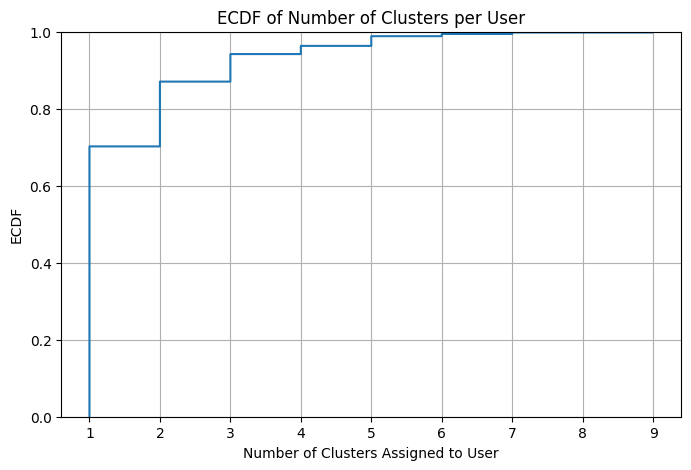

In [118]:
#print(kmeans_results[1].labels_)
indexOfChoosenCluster=7
print(data.insert(loc=1,column="cluster",value=kmeans_results[indexOfChoosenCluster].labels_))

user_clusters = data.groupby('author')['cluster'].nunique().reset_index()
user_clusters.columns = ['author', 'num_clusters']

# Step 2: Plot ECDF
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

Use the first two components of the PCA (found in Section 1.4). Then visualize on these two dimensions to gain insights into their distribution and separability.

In [ ]:
#Read the components from PCA.csv
pca = pd.read_csv("PCA.csv", encoding="utf8").iloc[:,1:3]
print(pca)

"""
#TODO change the number of clusters
kmeans = KMeans(n_clusters=8, random_state=0)
cl_labels = kmeans.fit_predict(pca)

# Step 3: Create projection DataFrame
projection = pd.DataFrame(pca, columns=['PC1', 'PC2'])
projection['cidBest'] = [f'C{x}' for x in cl_labels]
projection['label'] = y.reshape(-1)

# Step 4: Plotting
fig, axs = plt.subplots(3, 1, figsize=(6, 10))

for i in np.unique(projection.cid3):
    subdf = projection[projection.cid3 == i]
    axs[0].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[0].grid()
axs[0].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[0].set_xlabel('PC1')
axs[0].set_ylabel('PC2')
axs[0].set_title('k-Means with k=3')

for i in np.unique(projection.cidBest):
    subdf = projection[projection.cidBest == i]
    axs[1].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[1].grid()
axs[1].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[1].set_xlabel('PC1')
axs[1].set_ylabel('PC2')
axs[1].set_title(f'k-Means with K={best_n}')

for i in np.unique(y):
    subdf = projection[projection.label == i]
    axs[2].scatter(subdf['PC1'], subdf['PC2'], label=i, s=5)
axs[2].grid()
axs[2].legend(bbox_to_anchor=(1, 1), loc="upper left")
axs[2].set_xlabel('PC1')
axs[2].set_ylabel('PC2')
axs[2].set_title('GT Labels')

plt.tight_layout()
plt.show()
"""

             0         1
0    -0.064747  0.002242
1    -0.161647  0.017667
2    -0.247141  0.034467
3    -0.127360  0.003437
4    -0.144156  0.037885
...        ...       ...
4995 -0.157167 -0.021771
4996 -0.133449 -0.167872
4997 -0.129056  0.044970
4998 -0.228862 -0.025697
4999 -0.138347  0.017272

[5000 rows x 2 columns]


NameError: name 'y' is not defined